In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import xgboost as xgb
import numpy as np
import seaborn as sns
import pandas as pd

from arch import arch_model

from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

DATA_DIR = Path("FRED")
RESULTS_PATH = Path("results/dl_ta_models_results.json")
TRAIN_FRACTION = 0.8
VALIDATION_FRACTION = 0.1
model_results = {}

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


In [3]:
def load_data(file_name, BASE_DIR=DATA_DIR):
    file_path = BASE_DIR / file_name
    data = pd.read_csv(file_path)
    return data

In [8]:
useu = load_data("DEXUSEU.csv")
useu.head()

,observation_date,DEXUSEU
0,1999-01-04,1.1812
1,1999-01-05,1.1760
2,1999-01-06,1.1636
3,1999-01-07,1.1672
4,1999-01-08,1.1554


In [9]:
useu["observation_date"] = pd.to_datetime(useu["observation_date"])
useu.set_index("observation_date", inplace=True)

<Axes: xlabel='observation_date'>

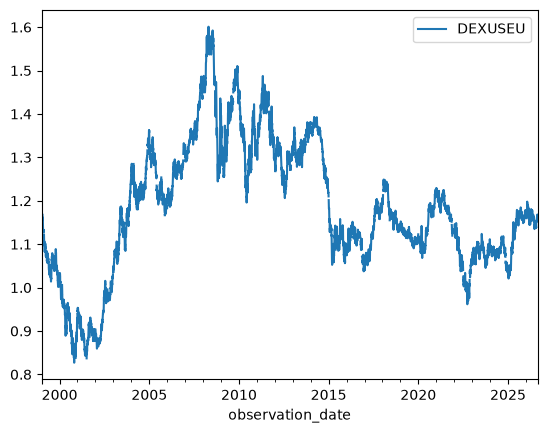

In [10]:
useu.plot()